## Analyze Classroom, Course, and Water Filler Data

We want to see which buildings and floors are most impacted by the lack of water fillers given the classes scheduled at a given time.

We start with three dataframes: classrooms, courses, and fillers

In [6]:
import pandas as pd

classrooms = pd.read_csv('data/classrooms.csv')
classrooms = classrooms[['Building Code', 'Room Number', 'Address', 'Capacity', 'A/C']]
classrooms = classrooms.dropna(subset=['Address'])

courses = pd.read_csv('data/courses-spring2024.csv')
courses = courses.dropna(subset=['building', 'room', 'start time', 'stop time'])

fillers = pd.read_csv('data/bottle_fillers.csv')
fillers = fillers.dropna(subset=['Address A', 'Address B'])

In [7]:
classrooms.head(3)

,Building Code,Room Number,Address,Capacity,A/C
0,BUMC - A Building - ABG,101,72 East Concord Street,269.0,True
1,BUMC - A Building - ABG,301A,72 East Concord Street,12.0,True
2,BUMC - A Building - ABG,406,72 East Concord Street,12.0,True


In [8]:
courses.head(3)

,Unnamed: 0,class code,title,instructor,open seats,credits,course type,building,room,day,start time,stop time,notes
0,0,CAS AA103 A1,Intro Af/Am Lit,Boelcskevy,1,4.0,Independent,SOC,241,"Tue,Thu",11:00am,12:15pm,Mts w/CAS EN129
1,1,CAS AA112 A1,Hist Black Stdy,Austin,6,4.0,Independent,CAS,233,"Tue,Thu",11:00am,12:15pm,Mts w/CAS HI112\nWebReg Restricted
2,2,CAS AA207 A1,Race&Ethnic Rel,Saleem,2,4.0,Lecture,COM,101,"Tue,Thu",11:00am,12:15pm,Mts w/CAS SO207


In [9]:
fillers.head(3)

,Address A,Address B,Floor,Description,Accessibility,Handicap Accessible,Space@Bu room,Quantity,Date Installed,Type,Walk-Thru Notes,Completed
0,100,Ashford St,First,"Hallway across from vending machines, across f...",Public,Yes,191,1.0,NaN,Combo Bottle Filler/Drinking Fountain,two additional drinking fountain locations in ...,1/5/2024
1,120,Ashford St,First,"Kitchenette, Room 116A",Restricted,Yes,116A,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024
2,120,Ashford St,Second,"Kitchenette, Room 222",Restricted,Yes,222,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024


### Processing

We want to answer the following questions

1. For all floors without a water filling station, we want to see a time series of people on that floor for a given day based on classes
    a. We want to take the area under the curve and rank these to identify key floors 

2. For all floors without a water filling station, we want to see a time series of people that are in classes without A/C for a given day
    a. We want to take the area under the curve and rank these to identify key floors

3. For any floors, we want to find the highest area under the curve have n rankings per the number of water bottle filling stations there are

We want to accomplish the following tasks

* Add a features to Classrooms: determine whether there is a water bottle filler on the same floor

* Add a feature to Courses: deterimine whether there is a water bottle filler on the same floor, determine if the class has AC
    * Here the key is (Building Code, Room Number)

* Define a unit of time (15 minutes) and break courses by 15 minute time increments

* Group courses by (weekday, building, room, floor)

    * For each group, we can plot a time series of traffic


### Clean Floors Column for each dataframe

#### First, the fillers dataframe

In [10]:
import numpy as np

ordinal_to_num = {
    'basement': 'b',
    'first': '1',
    'second': '2',
    'third': '3',
    'fourth': '4',
    'fifth': '5',
    'sixth': '6',
    'seventh': '7',
    'eighth': '8',
    'ninth': '9',
    'tenth': '10',
    'eleventh': '11',
    'twelfth': '12',
    'thirteenth': '13',
    'fourteenth': '14',
    'fifteenth': '15',
    'sixteenth': '16',
    'seventeenth': '17',
}

def clean_floors(floor: str) -> str:
    ''' Converts ordinal floor names to their corresponding number 
    '''
    floor = floor.strip().lower()
    if floor in ordinal_to_num:
        return ordinal_to_num[floor]
    else:
        return None


In [11]:
# Apply floor transformation to each row in fillers
fillers['Floor'] = fillers['Floor '].apply(clean_floors).apply(pd.Series)
fillers = fillers.drop(['Floor '], axis=1)

#### Next, the classrooms dataframe

In [14]:
def floor_from_room_num(room_num) -> str:
    ''' Get the floor from the room number. Essentially this just takes the hundreths place of the room number.
    '''
    if room_num.lower() == 'tsai':
        return '1'

    first_char = room_num.strip()[0].lower()

    if first_char.isnumeric() or first_char == 'b':
        return first_char
    else:
        return None

In [15]:
# Apply floor transformation to each row in classrooms
classrooms['Floor'] = classrooms['Room Number'].apply(floor_from_room_num).apply(pd.Series)
classrooms = classrooms.dropna(subset=['Floor'])

### Clean Addresses for each dataframe
The purpose of this is that the address is the shared key that helps us map fillers to classrooms

#### First, Fillers

In [16]:
import re

def get_address_parts(address):
    ''' Takes in a range of addresses and returns start, end addresses, and street name
        Ex: 20 - 30 Buswell St -> 20, 30
    '''
    regex = r"(\d+)\s*-\s*(\d+)(.*)"
    parts = re.fullmatch(regex, address)
    if parts == None:
        start = address.split(' ')[0]
        end = start
        street = ' '.join(address.split(' ')[1:])
    else:
        start = parts.group(1)
        end = parts.group(2)
        street = parts.group(3)

    return start, end, street.lower().strip()

ABREVIATIONS = {
    'st': 'street',
    'rd': 'road',
    'ave': 'avenue'
}

def convert_street_to_full(street):
    ''' Converts a suffix in an address to the complete word
        ex. st -> street, ave -> avenue
    '''
    words = street.split(' ')
    suffix = words[-1]
    if suffix.lower().strip() in ABREVIATIONS.keys():
        replacement = ABREVIATIONS[suffix.lower()]
        new_street = " ".join(words[:-1]) + " " + replacement
        return new_street.lower()
    else:
        return street.lower()


In [17]:
# Apply address transformations to fillers
# First combine into a single string
fillers['Address'] = list(fillers['Address A'] + ' ' + fillers['Address B'])

# Convert the street suffix to it's full name
fillers['Address'] = fillers['Address'].apply(convert_street_to_full)

# Extract address into three columns to easily compute address range and overlap
fillers[['Address Start', 'Address End', 'Street']] = fillers['Address'].apply(get_address_parts).apply(pd.Series)

# Drop old columns
fillers = fillers.drop(['Address A', 'Address B', 'Address'], axis=1)


#### Clean addresses for classrooms

In [18]:
# Apply address transformations to classrooms
# This is the same transformation as the above cell as with fillers, instead applied to classrooms
classrooms['Address'] = classrooms['Address'].apply(convert_street_to_full)
classrooms[['Address Start', 'Address End', 'Street']] = classrooms['Address'].apply(get_address_parts).apply(pd.Series)
classrooms.drop(['Address'], axis=1, inplace=True)

### Add Feature to classrooms: Wheather filler in building + Wheather filler on floor

This is the most important aspect of our analysis as it helps us to identify the locations that would be ideal to add a water station.

It also provides insights into how many students are affected by the current water bottle filling station locations as of Spring 2024

In [20]:
from functools import reduce

# Get filler locations in a list of tuples
filler_locations = fillers[['Address Start', 'Address End', 'Street', 'Floor']].to_numpy()
filler_locations = [list(x) for x in filler_locations]

# Map street name to the start and end street numbers, as well as the floor for a given column
# Any entry in this dictionary has a water bottle filling station
filler_dict = {}
for start, end, street, floor in filler_locations:
    if street not in filler_dict:
        filler_dict[street] = []
    filler_dict[street] += [[int(start), int(end), floor]]


def has_filler(class_start: str, class_end: str, class_street: str, class_floor: str):
    ''' Returns (in_building, on_same_floor), which are two booleans that represent if a filler is in the same building,
        or on the same floor given a classroom start address, end address, and floor
    '''
    class_start = int(class_start)
    class_end = int(class_end)

    if class_street not in filler_dict:
        return False, False

    
    has_filler = [] # in_building, in_floor

    for filler_start, filler_end, filler_floor in filler_dict[class_street]:
        is_in_building = filler_start <= class_start <= filler_end or class_start <= filler_start <= class_end
        is_on_floor = is_in_building and filler_floor == class_floor

        has_filler += [[is_in_building, is_on_floor]]

    in_building = reduce(lambda acc, x: acc or x[0], has_filler, False)
    on_floor = reduce(lambda acc, x: acc or (x[0] and x[1]), has_filler, False)

    return in_building, on_floor


In [21]:
# Add these two columns to classrooms
apply_fn = lambda row: has_filler(*row[['Address Start', 'Address End', 'Street', 'Floor']])
classrooms[['Filler In Building', 'Filler On Floor']] = classrooms.apply(apply_fn, axis=1).apply(pd.Series)

### Merge Courses and Classrooms

We can do a simple inner join to now the number of students in a class at a given time, mapped to wheather there are water fountains nearby

In [80]:
classrooms['Code And Room'] = classrooms['Building Code'] + ' ' + classrooms['Room Number']
courses['Code And Room'] = courses['building'] + ' ' + courses['room']

Now we create a final dataset, called df that has key columns of all three datasets we wish to combine

In [81]:
df = pd.merge(courses, classrooms, how='inner', on='Code And Room')
df['students'] = df['Capacity'] - df['open seats']
df.dropna(subset=['students'])
df['building floor'] = df['building'] + ' ' + df['Floor']
df = df[['building floor', 'students', 'Capacity', 'day', 'start time', 'stop time', 'Filler In Building', 'Filler On Floor', 'A/C']]

In [82]:
df.head(3)

,building floor,students,Capacity,day,start time,stop time,Filler In Building,Filler On Floor,A/C
0,SOC 2,34.0,35.0,"Tue,Thu",11:00am,12:15pm,True,False,True
1,SOC 2,35.0,35.0,Wed,1:25pm,2:15pm,True,False,True
2,SOC 2,34.0,35.0,Tue,12:30pm,3:15pm,True,False,True


### Update Times and Days

We need some preprocessing of date times such that we can easily add and subtract times

In [83]:
df['start time'] = pd.to_datetime(df['start time']).dt.time
df['stop time'] = pd.to_datetime(df['stop time']).dt.time

C:\Users\chris\AppData\Local\Temp\ipykernel_19516\3791954269.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['start time'] = pd.to_datetime(df['start time']).dt.time
C:\Users\chris\AppData\Local\Temp\ipykernel_19516\3791954269.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['stop time'] = pd.to_datetime(df['stop time']).dt.time


Although it was not used, we can also analyze each day seperately. We decided to just do all the analysis as a per week time frame.

In [84]:
df['Mon'] = df['day'].apply(lambda s: 'Mon' in s)
df['Tue'] = df['day'].apply(lambda s: 'Tue' in s)
df['Wed'] = df['day'].apply(lambda s: 'Wed' in s)
df['Thu'] = df['day'].apply(lambda s: 'Thu' in s)
df['Fri'] = df['day'].apply(lambda s: 'Fri' in s)
df = df.drop(['day'], axis=1)

Checkpoint progress on data preprocessing

In [85]:
df.to_csv('data/courses-classrooms.csv')

## If All Processing Done, Start Analysis Here

In [22]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/courses-classrooms.csv', index_col=False)
df.head(3)

,Unnamed: 0,building floor,students,Capacity,start time,stop time,Filler In Building,Filler On Floor,A/C,Mon,Tue,Wed,Thu,Fri
0,0,SOC 2,34.0,35.0,11:00:00,12:15:00,True,False,True,False,True,False,True,False
1,1,SOC 2,35.0,35.0,13:25:00,14:15:00,True,False,True,False,False,True,False,False
2,2,SOC 2,34.0,35.0,12:30:00,15:15:00,True,False,True,False,True,False,False,False


### Convert Times to relative times in minutes

In [23]:
df['start time'] = pd.to_datetime(df['start time'])
df['stop time'] = pd.to_datetime(df['stop time'])

earliest_start = df['start time'].min()
print(f"Earliest class is at {earliest_start.time()}, this is what our time = 0 will be")

Earliest class is at 06:00:00, this is what our time = 0 will be


C:\Users\chris\AppData\Local\Temp\ipykernel_3736\1912269318.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['start time'] = pd.to_datetime(df['start time'])
C:\Users\chris\AppData\Local\Temp\ipykernel_3736\1912269318.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['stop time'] = pd.to_datetime(df['stop time'])


In [24]:
df['start time'] = df['start time'].apply(lambda d: (d - earliest_start).total_seconds() / 60)
df['stop time'] = df['stop time'].apply(lambda d: (d - earliest_start).total_seconds() / 60)

In [25]:
df.head(3)

,Unnamed: 0,building floor,students,Capacity,start time,stop time,Filler In Building,Filler On Floor,A/C,Mon,Tue,Wed,Thu,Fri
0,0,SOC 2,34.0,35.0,300.0,375.0,True,False,True,False,True,False,True,False
1,1,SOC 2,35.0,35.0,445.0,495.0,True,False,True,False,False,True,False,False
2,2,SOC 2,34.0,35.0,390.0,555.0,True,False,True,False,True,False,False,False


In [26]:
data = df.to_numpy()[:, 1:]

In [27]:
# Construct a data by floor object that allows easy lookup of all attributes given the "building floor" key
data_by_floor = {}
for row in data:
    building_floor = row[0]
    if building_floor not in data_by_floor:
        data_by_floor[building_floor] = np.expand_dims(row[1:], axis=0)
    else:
        x = data_by_floor[building_floor]
        data_by_floor[building_floor] = np.vstack([x, row[1:]])


In [28]:
# Get the "floor statueses", a method of easily checking whether a building and floor has a filler
floor_statuses = {}
for row in data:
    building_floor = row[0]
    if building_floor not in floor_statuses:
        floor_statuses[building_floor] = (row[5], row[6])

In [29]:
def get_time_series(values, starts, ends, t):
    ''' For each class's capacity, start and end time, return cumulative sum of all students at a particular time.
        Returns (time series vector, area under the curve)
    '''
    n_t = len(t)
    N = len(values)

    T = np.repeat(np.expand_dims(t, axis=1), N, axis=1).T # Time Matrix
    S = np.repeat(np.expand_dims(starts, axis=1), n_t, axis=1) # Start Time Matrix
    E = np.repeat(np.expand_dims(ends, axis=1), n_t, axis=1) # End Time Matrix
    V = np.repeat(np.expand_dims(values, axis=1), n_t, axis=1) # Number of students Matrix

    during_class = (S <= T) * (T <= E)
    return np.sum(during_class * V, axis=0), np.sum(during_class * V)


### Analysis of Classroom Activity

Using our time series function, we can now compare all buildings and floors based on a quantitative metric: Area under the curve

In [33]:
max_t = df['stop time'].max()
dt = 15
t = np.arange(0, max_t, dt)

# Only consider floors without a filler on the room
all_results = [(key, get_time_series(x[:, 0], x[:, 2], x[:, 3], t)) for key, x in data_by_floor.items() if floor_statuses[key][1] == False]
all_results = [[key, x[1], x[0]] for key, x in all_results if not np.isnan(x[1])]

# Sort results based on the AUC, take the top K
top_auc = sorted(all_results, key=lambda x: x[1], reverse=True)
k = 10

print("---- Building Floors with high density and no filler ----- ")
for i in range(k):
    print(f"{i}. {top_auc[i][0]} with AUC {top_auc[i][1]}")

---- Building Floors with high density and no filler ----- 
0. PHO 2 with AUC 33539.0
1. MOR 1 with AUC 31299.0
2. EPC 2 with AUC 27750.0
3. CDS 2 with AUC 23397.0
4. CAS 5 with AUC 18920.0
5. SCI 3 with AUC 18830.0
6. HAR 1 with AUC 17342.0
7. SOC b with AUC 16329.0
8. SCI 4 with AUC 15720.0
9. MET 1 with AUC 11202.0


### Plot Time Series Data

Also, it seems PHO floor 2 does not have a filler (as it was not on the spread sheet), however, PHO floor 2 does indeed have a filler so disregard it as the first location.

Note the AUC has units (number of students * minutes / 15)

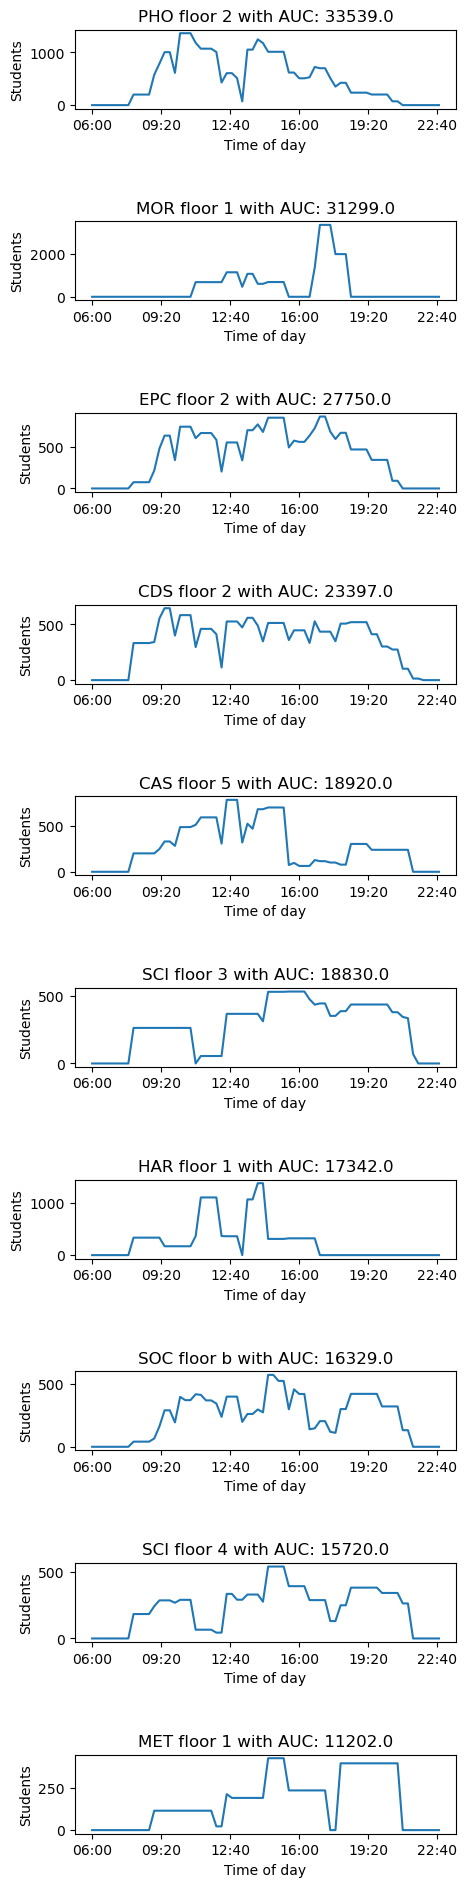

In [35]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(10, 1, figsize=(6, 20))
fig.tight_layout(pad=6)

t_ticks = list(np.arange(0, 1001, 200))
times = [(earliest_start + pd.DateOffset(minutes=int(t_tick))).time() for t_tick in t_ticks]
str_times = [time.strftime("%H:%M") for time in times]

for i in range(10):
    y = top_auc[i][2]
    ax[i].plot(t, y)
    ax[i].set_xlabel('Time of day')
    ax[i].set_ylabel('Students')
    ax[i].set_xticks(t_ticks, str_times)
    building, floor = top_auc[i][0].split(' ')
    ax[i].set_title(f"{building} floor {floor} with AUC: {top_auc[i][1]}")

plt.savefig('deliverables/floors-without-filler-and-high-classroom-activity.png')
